# مقارنة خوارزميات التحسين لمسألة تحسين مسار توصيل من مستودع واحد (Single-Depot TSP)

---
---
# القسم 1: Genetic Algorithm (GA)
---


استيراد المكتبات وتحميل بيانات الاختبار

In [1]:
from pathlib import Path
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display



def resolve_data_path():
    filename = "Delivery_Route_Test_Data.xlsx"
    current_dir = Path.cwd().resolve()
    search_roots = [current_dir, *current_dir.parents]

    for root in search_roots:
        candidate = root / "data" / filename
        if candidate.is_file():
            return candidate

    for root in search_roots:
        candidate = root / filename
        if candidate.is_file():
            return candidate

    raise FileNotFoundError(
        f"{filename} was not found. Place it in the project's data folder: data/{filename}"
    )

DATA_PATH = resolve_data_path()


def load_dataset(number_of_customers):
    sheet_name = f"Customers_{number_of_customers}"
    df = pd.read_excel(DATA_PATH, sheet_name=sheet_name)
    node_type = df["Node_Type"].astype(str).str.strip().str.lower()
    depot_rows = df.loc[node_type == "depot"]
    customer_rows = df.loc[node_type == "customer"].copy()
    depot = depot_rows[["X", "Y"]].iloc[0].astype(float).to_numpy()
    customer_coords = customer_rows[["X", "Y"]].astype(float).to_numpy()
    return {
        "customer_ids": customer_rows["Node_ID"].astype(str).tolist(),
        "customer_coords": customer_coords,
        "depot": depot,
        "nodes_df": df
    }

datasets = {n: load_dataset(n) for n in [10, 30, 100]}

Objective and Fitness Functions

In [2]:
def euclidean_distance(point_a, point_b):
    return float(np.linalg.norm(point_a - point_b))

def route_distance(route, customer_coords, depot):
    route = np.asarray(route, dtype=int)
    if route.size == 0:
        return 0.0
    route_points = customer_coords[route]
    full_path = np.vstack((depot, route_points, depot))
    return float(np.linalg.norm(np.diff(full_path, axis=0), axis=1).sum())

def validate_route(route, n_customers):
    route = np.asarray(route, dtype=int)
    return len(route) == n_customers and np.array_equal(np.sort(route), np.arange(n_customers))


Population Initialization | Selection 

In [3]:
def initialize_population(pop_size, n_customers, rng):
    return [rng.permutation(n_customers) for _ in range(pop_size)]

def evaluate_population(population, customer_coords, depot):
    return [route_distance(ind, customer_coords, depot) for ind in population]

def select_parents(sorted_population, pop_size, rng):
    parent1 = sorted_population[rng.integers(0, max(1, pop_size // 2))]
    parent2 = sorted_population[rng.integers(0, max(1, pop_size // 2))]
    return parent1, parent2

def perform_crossover(parent1, parent2, n_customers, rng):
    cut = int(rng.integers(1, n_customers)) if n_customers > 1 else 0
    prefix = list(parent1[:cut])
    child = prefix + [item for item in parent2 if item not in prefix]
    return np.asarray(child, dtype=int)

def perform_mutation(child, mutation_rate, n_customers, rng):
    if n_customers >= 2 and rng.random() < mutation_rate:
        idx1, idx2 = rng.choice(n_customers, 2, replace=False)
        child[idx1], child[idx2] = child[idx2], child[idx1]
    return child


Convergence Stopping Criteria

In [4]:
def run_genetic_algorithm(
    n_customers,
    seed,
    pop_size=60,
    max_evaluations=18000,
    mutation_rate=0.1,
    patience_evals=2400,
):
    data = datasets[n_customers]
    customer_coords = data["customer_coords"]
    depot = data["depot"]
    rng = np.random.default_rng(seed)
    start_time = time.perf_counter()
    population = initialize_population(pop_size, n_customers, rng)
    best_distance = float("inf")
    best_route = None
    history = []
    eval_count = 0
    no_improvement_evals = 0
    generation = 0
    stopping_reason = "Maximum evaluation budget reached"

    while eval_count < max_evaluations:
        generation += 1
        current_population = population[:max_evaluations - eval_count]
        fitness_scores = evaluate_population(current_population, customer_coords, depot)
        eval_count += len(current_population)
        current_best_index = int(np.argmin(fitness_scores))
        current_best_distance = float(fitness_scores[current_best_index])

        if current_best_distance < best_distance:
            best_distance = current_best_distance
            best_route = current_population[current_best_index].copy()
            no_improvement_evals = 0
        else:
            no_improvement_evals += len(current_population)

        history.append({
            "Evaluations": eval_count,
            "Iteration": generation,
            "Best_Distance": best_distance,
        })

        if no_improvement_evals >= patience_evals:
            stopping_reason = f"Early stopping: no improvement for {patience_evals} evaluations"
            break

        if eval_count >= max_evaluations:
            break

        sorted_population = [
            individual
            for _, individual in sorted(
                zip(fitness_scores, current_population),
                key=lambda item: item[0],
            )
        ]
        next_population = sorted_population[:2]

        while len(next_population) < pop_size:
            parent1, parent2 = select_parents(sorted_population, len(sorted_population), rng)
            child = perform_crossover(parent1, parent2, n_customers, rng)
            child = perform_mutation(child, mutation_rate, n_customers, rng)
            next_population.append(child)

        population = next_population

    execution_time = time.perf_counter() - start_time
    if best_route is None or not validate_route(best_route, n_customers):
        raise RuntimeError("Genetic Algorithm returned an invalid route.")

    return {
        "best_route": best_route,
        "best_distance": float(best_distance),
        "history": pd.DataFrame(history),
        "evaluations": eval_count,
        "iterations": generation,
        "no_improvement_evals": no_improvement_evals,
        "stop_reason": stopping_reason,
        "execution_time": execution_time,
    }


---
---
# القسم 2: Discrete Particle Swarm Optimization (PSO)
---


# 1. Import Libraries and Configure Settings

In [5]:
from pathlib import Path
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Match the Genetic Algorithm's experimental settings.
EVALUATION_BUDGET = 18_000
PATIENCE_EVALS = 2_400

# PSO-specific hyperparameters.
PSO_PARAMS = {
    "swarm_size": 60,
    "w": 0.7,
    "c1": 1.5,
    "c2": 1.5,
    "v_max": 10,
    "exploration_probability": 0.10,
}

print("Discrete PSO settings are ready.")
print(f"Maximum objective evaluations: {EVALUATION_BUDGET}")
print(f"Early-stopping patience: {PATIENCE_EVALS} evaluations without improvement")
print(f"PSO parameters: {PSO_PARAMS}")


Discrete PSO settings are ready.
Maximum objective evaluations: 18000
Early-stopping patience: 2400 evaluations without improvement
PSO parameters: {'swarm_size': 60, 'w': 0.7, 'c1': 1.5, 'c2': 1.5, 'v_max': 10, 'exploration_probability': 0.1}


# 2. Load the Excel Dataset

In [6]:
DATA_PATH = resolve_data_path()


def load_dataset(number_of_customers):
    """Load one fixed worksheet and validate its depot and customer rows."""
    sheet_name = f"Customers_{number_of_customers}"
    df = pd.read_excel(DATA_PATH, sheet_name=sheet_name)

    required_columns = {"Node_ID", "Node_Type", "X", "Y"}
    missing_columns = required_columns - set(df.columns)
    if missing_columns:
        raise ValueError(
            f"Required columns are missing from {sheet_name}: {sorted(missing_columns)}"
        )

    node_type = df["Node_Type"].astype(str).str.strip().str.lower()
    depot_rows = df.loc[node_type == "depot"]
    customer_rows = df.loc[node_type == "customer"].copy()

    if len(depot_rows) != 1:
        raise ValueError(f"Worksheet {sheet_name} must contain exactly one depot row.")
    if len(customer_rows) != number_of_customers:
        raise ValueError(
            f"Expected {number_of_customers} customers in {sheet_name}, "
            f"but found {len(customer_rows)}."
        )

    # Coordinates must be numeric and finite before route calculations begin.
    depot = depot_rows[["X", "Y"]].iloc[0].astype(float).to_numpy()
    customer_coords = customer_rows[["X", "Y"]].astype(float).to_numpy()
    if not np.isfinite(depot).all() or not np.isfinite(customer_coords).all():
        raise ValueError(f"Worksheet {sheet_name} contains missing or non-finite coordinates.")

    return {
        "customer_ids": customer_rows["Node_ID"].astype(str).tolist(),
        "customer_coords": customer_coords,
        "depot": depot,
    }


datasets = {n: load_dataset(n) for n in [10, 30, 100]}

for n_customers, data in datasets.items():
    print(
        f"{n_customers} customers loaded | Depot={data['depot'].tolist()} | "
        f"Coordinate shape={data['customer_coords'].shape}"
    )


10 customers loaded | Depot=[50.0, 50.0] | Coordinate shape=(10, 2)
30 customers loaded | Depot=[50.0, 50.0] | Coordinate shape=(30, 2)
100 customers loaded | Depot=[50.0, 50.0] | Coordinate shape=(100, 2)


# 3. Objective Function and Solution Representation
Calculate the total Euclidean distance of a round trip that starts and ends at the depot.


In [7]:
# Calculate the straight-line distance between two coordinate pairs.
def euclidean_distance(point_a, point_b):
    """Return the Euclidean distance between two (X, Y) points."""
    return float(np.linalg.norm(point_a - point_b))


# Include the trip from the depot and the return trip to the depot.
def route_distance(route, customer_coords, depot):
    route = np.asarray(route, dtype=int)
    if route.size == 0:
        return 0.0
    route_points = customer_coords[route]
    full_path = np.vstack((depot, route_points, depot))
    return float(np.linalg.norm(np.diff(full_path, axis=0), axis=1).sum())



### Swap Operations and Discrete Movement


In [8]:
# Build an ordered swap sequence that transforms source into target.
def swaps_to_transform(source, target):
    """Return position swaps that transform one permutation into another."""
    current = list(source)
    target = list(target)

    if len(current) != len(target) or set(current) != set(target):
        raise ValueError("Source and target must contain the same permutation elements.")

    swaps = []
    for i in range(len(current)):
        if current[i] == target[i]:
            continue

        # Find the required target element later in the current permutation.
        j = current.index(target[i], i + 1)
        swaps.append((i, j))
        current[i], current[j] = current[j], current[i]

    return swaps


# Select part of an ordered influence sequence according to a coefficient.
def select_influence_swaps(swap_sequence, coefficient, rng):
    """Randomly select an ordered subset based on the normalized influence coefficient."""
    if not swap_sequence:
        return []

    # Divide by 2 to adapt continuous-scale coefficients to a selection fraction.
    selected_fraction = min(1.0, coefficient * rng.random() / 2.0)
    selected_count = min(
        len(swap_sequence),
        int(round(selected_fraction * len(swap_sequence))),
    )
    if selected_count == 0:
        return []

    # Keep selected operations in their original sequence order.
    selected_indices = sorted(
        rng.choice(len(swap_sequence), size=selected_count, replace=False).tolist()
    )
    return [swap_sequence[index] for index in selected_indices]


# Combine inertia, personal influence, and global influence into a bounded velocity.
def build_velocity(position, pbest, gbest, old_velocity, w, c1, c2, v_max, rng):
    """Create the next swap-based velocity and limit its length to v_max."""
    inertia_count = min(len(old_velocity), int(round(w * len(old_velocity))))
    if inertia_count:
        inertia_indices = sorted(
            rng.choice(len(old_velocity), size=inertia_count, replace=False).tolist()
        )
        inertia_swaps = [old_velocity[index] for index in inertia_indices]
    else:
        inertia_swaps = []

    personal_difference = swaps_to_transform(position, pbest)
    global_difference = swaps_to_transform(position, gbest)

    personal_swaps = select_influence_swaps(personal_difference, c1, rng)
    global_swaps = select_influence_swaps(global_difference, c2, rng)

    combined_velocity = inertia_swaps + personal_swaps + global_swaps

    # Randomly reduce an oversized sequence while preserving its relative order.
    if len(combined_velocity) > v_max:
        retained_indices = sorted(
            rng.choice(len(combined_velocity), size=v_max, replace=False).tolist()
        )
        combined_velocity = [combined_velocity[index] for index in retained_indices]

    return combined_velocity


# Apply each swap in order; swapping positions preserves the permutation constraint.
def apply_swap_sequence(route, swap_sequence):
    """Apply an ordered sequence of position swaps and return a new route."""
    new_route = list(route)
    for i, j in swap_sequence:
        new_route[i], new_route[j] = new_route[j], new_route[i]
    return new_route


# Initialize each particle's velocity with zero to a few random swap operations.
def random_initial_velocity(number_of_customers, v_max, rng):
    """Create a small random initial velocity without exceeding v_max."""
    maximum_initial_swaps = min(3, v_max, max(0, number_of_customers - 1))
    if maximum_initial_swaps == 0:
        return []

    number_of_swaps = int(rng.integers(0, maximum_initial_swaps + 1))
    velocity = []
    for _ in range(number_of_swaps):
        i, j = rng.choice(number_of_customers, size=2, replace=False).tolist()
        velocity.append((int(i), int(j)))
    return velocity


# Verify that a generated swap sequence reaches the intended target permutation.
_test_source = [0, 1, 2, 3, 4]
_test_target = [3, 0, 4, 1, 2]
_test_swaps = swaps_to_transform(_test_source, _test_target)
_test_result = apply_swap_sequence(_test_source, _test_swaps)
assert _test_result == _test_target, "Swap-sequence transformation test failed."
print("Swap-sequence test passed:", _test_result)


Swap-sequence test passed: [3, 0, 4, 1, 2]


# 5. Discrete PSO Workflow (Implement Discrete PSO)

In [9]:
# Run the swap-based Discrete PSO optimization once for the current dataset size.
def run_discrete_pso(
    customer_coords,
    depot,
    evaluation_budget,
    seed,
    patience_evals=2_400,
    swarm_size=60,
    w=0.7,
    c1=1.5,
    c2=1.5,
    v_max=10,
    exploration_probability=0.10,
):
    """Run discrete PSO once with an evaluation budget and no-improvement stop rule."""
    if evaluation_budget < 1:
        raise ValueError("evaluation_budget must be a positive integer.")
    if swarm_size < 1:
        raise ValueError("swarm_size must be at least 1.")
    if patience_evals < 1:
        raise ValueError("patience_evals must be at least 1.")
    if v_max < 0:
        raise ValueError("v_max cannot be negative.")
    if not 0.0 <= exploration_probability <= 1.0:
        raise ValueError("exploration_probability must be between 0 and 1.")

    rng = np.random.default_rng(seed)
    number_of_customers = len(customer_coords)

    # Initial-swarm evaluations count toward the same budget as GA evaluations.
    initial_swarm_size = min(swarm_size, evaluation_budget)
    particles = []
    evaluations = 0

    for _ in range(initial_swarm_size):
        initial_position = rng.permutation(number_of_customers).tolist()
        initial_cost = route_distance(initial_position, customer_coords, depot)
        evaluations += 1

        particles.append({
            "position": initial_position,
            "velocity": random_initial_velocity(number_of_customers, v_max, rng),
            "pbest": initial_position.copy(),
            "pbest_cost": float(initial_cost),
            "current_cost": float(initial_cost),
        })

    # Initialize the global best from the evaluated initial swarm.
    best_particle = min(particles, key=lambda particle: particle["pbest_cost"])
    gbest_route = best_particle["pbest"].copy()
    gbest_cost = float(best_particle["pbest_cost"])
    best_route = gbest_route.copy()
    best_distance = gbest_cost

    history = [{
        "Evaluations": evaluations,
        "Iteration": 0,
        "Best_Distance": best_distance,
    }]
    iterations = 0
    no_improvement_evals = 0
    stop_reason = "Maximum evaluation budget reached"

    while evaluations < evaluation_budget:
        iterations += 1
        iteration_gbest_route = gbest_route.copy()
        iteration_improved = False
        evaluations_this_iteration = 0

        for particle in particles:
            if evaluations >= evaluation_budget:
                break

            current_position = particle["position"].copy()
            next_velocity = build_velocity(
                position=current_position,
                pbest=particle["pbest"],
                gbest=iteration_gbest_route,
                old_velocity=particle["velocity"],
                w=w,
                c1=c1,
                c2=c2,
                v_max=v_max,
                rng=rng,
            )

            candidate_route = apply_swap_sequence(current_position, next_velocity)

            # Occasional random swap encourages exploration while preserving a permutation.
            if number_of_customers >= 2 and rng.random() < exploration_probability:
                i, j = rng.choice(number_of_customers, size=2, replace=False).tolist()
                candidate_route[i], candidate_route[j] = candidate_route[j], candidate_route[i]

            candidate_cost = route_distance(candidate_route, customer_coords, depot)
            evaluations += 1
            evaluations_this_iteration += 1

            particle["position"] = candidate_route
            particle["velocity"] = next_velocity
            particle["current_cost"] = float(candidate_cost)

            if candidate_cost < particle["pbest_cost"]:
                particle["pbest"] = candidate_route.copy()
                particle["pbest_cost"] = float(candidate_cost)

            if candidate_cost < best_distance:
                best_distance = float(candidate_cost)
                best_route = candidate_route.copy()
                iteration_improved = True

        # Refresh the stored global best from all personal bests after the swarm update.
        best_particle = min(particles, key=lambda particle: particle["pbest_cost"])
        if best_particle["pbest_cost"] < gbest_cost:
            gbest_route = best_particle["pbest"].copy()
            gbest_cost = float(best_particle["pbest_cost"])

        # Match GA's generation-level patience rule: a generation with any new global
        # best resets patience; otherwise all evaluations in that generation accumulate.
        if iteration_improved:
            no_improvement_evals = 0
        else:
            no_improvement_evals += evaluations_this_iteration

        history.append({
            "Evaluations": evaluations,
            "Iteration": iterations,
            "Best_Distance": best_distance,
        })

        if no_improvement_evals >= patience_evals:
            stop_reason = f"Early stopping: no improvement for {patience_evals} evaluations"
            break

    return {
        "best_route": best_route,
        "best_distance": float(best_distance),
        "evaluations": evaluations,
        "iterations": iterations,
        "history": pd.DataFrame(history),
        "no_improvement_evals": no_improvement_evals,
        "stop_reason": stop_reason,
    }


print("Discrete PSO function is defined with GA-matched stopping criteria.")


Discrete PSO function is defined with GA-matched stopping criteria.


---
---
# القسم 3: Ant Colony Optimization (ACO)
---


# 1. Import Libraries and Configure Settings

In [10]:
from pathlib import Path
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Match the Genetic Algorithm's and PSO's experimental settings.
EVALUATION_BUDGET = 18_000
PATIENCE_EVALS = 2_400

# ACO-specific hyperparameters.
ACO_PARAMS = {
    "n_ants": 60,
    "alpha": 1.0,
    "beta": 3.0,
    "rho": 0.10,
    "q": 100.0,
    "tau0": 1.0,
}


print("ACO settings are ready.")
print(f"Maximum objective evaluations: {EVALUATION_BUDGET}")
print(f"Early-stopping patience: {PATIENCE_EVALS} evaluations without improvement")
print(f"ACO parameters: {ACO_PARAMS}")


ACO settings are ready.
Maximum objective evaluations: 18000
Early-stopping patience: 2400 evaluations without improvement
ACO parameters: {'n_ants': 60, 'alpha': 1.0, 'beta': 3.0, 'rho': 0.1, 'q': 100.0, 'tau0': 1.0}


# 2. Load the Excel Dataset

In [11]:
DATA_PATH = resolve_data_path()


def load_dataset(number_of_customers):
    """Load one fixed worksheet and validate its depot and customer rows."""
    sheet_name = f"Customers_{number_of_customers}"
    df = pd.read_excel(DATA_PATH, sheet_name=sheet_name)

    required_columns = {"Node_ID", "Node_Type", "X", "Y"}
    missing_columns = required_columns - set(df.columns)
    if missing_columns:
        raise ValueError(
            f"Required columns are missing from {sheet_name}: {sorted(missing_columns)}"
        )

    node_type = df["Node_Type"].astype(str).str.strip().str.lower()
    depot_rows = df.loc[node_type == "depot"]
    customer_rows = df.loc[node_type == "customer"].copy()

    if len(depot_rows) != 1:
        raise ValueError(f"Worksheet {sheet_name} must contain exactly one depot row.")
    if len(customer_rows) != number_of_customers:
        raise ValueError(
            f"Expected {number_of_customers} customers in {sheet_name}, "
            f"but found {len(customer_rows)}."
        )

    # Coordinates must be numeric and finite before route calculations begin.
    depot = depot_rows[["X", "Y"]].iloc[0].astype(float).to_numpy()
    customer_coords = customer_rows[["X", "Y"]].astype(float).to_numpy()
    if not np.isfinite(depot).all() or not np.isfinite(customer_coords).all():
        raise ValueError(f"Worksheet {sheet_name} contains missing or non-finite coordinates.")

    return {
        "customer_ids": customer_rows["Node_ID"].astype(str).tolist(),
        "customer_coords": customer_coords,
        "depot": depot,
    }


datasets = {n: load_dataset(n) for n in [10, 30, 100]}

for n_customers, data in datasets.items():
    print(
        f"{n_customers} customers loaded | Depot={data['depot'].tolist()} | "
        f"Coordinate shape={data['customer_coords'].shape}"
    )


# Figures and tables produced by this notebook are saved next to the data folder.
PROJECT_ROOT = DATA_PATH.resolve().parent.parent if DATA_PATH.resolve().parent.name == "data" else Path.cwd()
RESULTS_DIR = PROJECT_ROOT / "results" / "aco"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


10 customers loaded | Depot=[50.0, 50.0] | Coordinate shape=(10, 2)
30 customers loaded | Depot=[50.0, 50.0] | Coordinate shape=(30, 2)
100 customers loaded | Depot=[50.0, 50.0] | Coordinate shape=(100, 2)


# 3. Objective Function and Solution Representation
Calculate the total Euclidean distance of a round trip that starts and ends at the depot.

A solution is an ordered list of customer indices (each customer exactly once); the depot is added automatically at the start and end, exactly as in the GA and PSO notebooks.

In [12]:
# Calculate the straight-line distance between two coordinate pairs.
def euclidean_distance(point_a, point_b):
    """Return the Euclidean distance between two (X, Y) points."""
    return float(np.linalg.norm(point_a - point_b))


# Include the trip from the depot and the return trip to the depot.
def route_distance(route, customer_coords, depot):
    route = np.asarray(route, dtype=int)
    if route.size == 0:
        return 0.0
    route_points = customer_coords[route]
    full_path = np.vstack((depot, route_points, depot))
    return float(np.linalg.norm(np.diff(full_path, axis=0), axis=1).sum())

### ACO Building Blocks: Distance Matrix, Pheromone, Route Construction, and Pheromone Update

In [13]:
# Build the full distance matrix once; node 0 is the depot and node k is customer k-1.
def build_distance_matrix(customer_coords, depot):
    """Return the (n + 1) x (n + 1) Euclidean distance matrix with the depot at index 0."""
    points = np.vstack([depot, customer_coords])
    return np.linalg.norm(points[:, None, :] - points[None, :, :], axis=2)


# Heuristic desirability: closer nodes are more attractive (eta = 1 / distance).
def heuristic_information(distance_matrix):
    """Return eta = 1 / d for every pair of distinct nodes and zero on the diagonal."""
    eta = 1.0 / np.maximum(distance_matrix, 1e-10)
    np.fill_diagonal(eta, 0.0)
    return eta


# Every edge starts with the same pheromone level, so the first ants rely on distance only.
def initialize_pheromone(number_of_nodes, tau0):
    """Create a symmetric pheromone matrix filled with tau0 (zero on the diagonal)."""
    pheromone = np.full((number_of_nodes, number_of_nodes), float(tau0))
    np.fill_diagonal(pheromone, 0.0)
    return pheromone


# One ant leaves the depot and chooses each next customer by the ACO transition rule.
def construct_ant_route(attractiveness, number_of_customers, rng):
    """Build a customer permutation where P(i -> j) is proportional to tau_ij^alpha * eta_ij^beta."""
    unvisited = np.ones(number_of_customers + 1, dtype=bool)
    unvisited[0] = False  # the depot is never chosen as a customer
    current_node = 0
    route = []

    for _ in range(number_of_customers):
        weights = attractiveness[current_node] * unvisited
        cumulative = np.cumsum(weights)
        total = cumulative[-1]

        if total > 0.0 and np.isfinite(total):
            # Roulette-wheel selection over the unvisited customers.
            next_node = int(np.searchsorted(cumulative, rng.random() * total, side="right"))
            if next_node >= len(weights) or not unvisited[next_node]:
                next_node = int(np.flatnonzero(unvisited)[-1])
        else:
            # Fallback if every weight underflowed: choose uniformly among unvisited customers.
            next_node = int(rng.choice(np.flatnonzero(unvisited)))

        route.append(next_node - 1)  # store customer indices (0..n-1), as in the PSO notebook
        unvisited[next_node] = False
        current_node = next_node

    return route


# Evaporation lets weak trails fade so the colony does not lock onto an early route.
def evaporate_pheromone(pheromone, rho):
    """Apply tau <- (1 - rho) * tau to every edge in place."""
    pheromone *= (1.0 - rho)


# Each ant reinforces the edges it used; shorter routes deposit more pheromone.
def deposit_pheromone(pheromone, route, route_length, q):
    """Add Q / L to every edge of the round trip depot -> route -> depot (both directions)."""
    nodes = np.array([0] + [customer + 1 for customer in route] + [0])
    amount = q / route_length
    np.add.at(pheromone, (nodes[:-1], nodes[1:]), amount)
    np.add.at(pheromone, (nodes[1:], nodes[:-1]), amount)


# Verify that ants always build valid routes (every customer exactly once).
_test_rng = np.random.default_rng(0)
_test_coords = _test_rng.uniform(0, 100, size=(8, 2))
_test_attr = initialize_pheromone(9, 1.0) * heuristic_information(
    build_distance_matrix(_test_coords, np.array([50.0, 50.0]))
) ** 3
for _ in range(200):
    _test_route = construct_ant_route(_test_attr, 8, _test_rng)
    assert sorted(_test_route) == list(range(8)), "Ant route is not a valid permutation."
print("Ant-route validity test passed:", _test_route)


Ant-route validity test passed: [3, 6, 5, 7, 0, 4, 2, 1]


# 5. ACO Workflow (Implement Ant Colony Optimization)

In [14]:
# Run the Ant Colony Optimization once for the current dataset size.
def run_aco(
    customer_coords,
    depot,
    evaluation_budget,
    seed,
    patience_evals=2_400,
    n_ants=60,
    alpha=1.0,
    beta=3.0,
    rho=0.10,
    q=100.0,
    tau0=1.0,
):
    """Run ACO once with an evaluation budget and no-improvement stop rule."""
    if evaluation_budget < 1:
        raise ValueError("evaluation_budget must be a positive integer.")
    if n_ants < 1:
        raise ValueError("n_ants must be at least 1.")
    if patience_evals < 1:
        raise ValueError("patience_evals must be at least 1.")
    if not 0.0 < rho < 1.0:
        raise ValueError("rho must be strictly between 0 and 1.")
    if q <= 0 or tau0 <= 0:
        raise ValueError("q and tau0 must be positive.")

    rng = np.random.default_rng(seed)
    number_of_customers = len(customer_coords)

    distance_matrix = build_distance_matrix(customer_coords, depot)
    eta_beta = heuristic_information(distance_matrix) ** beta
    pheromone = initialize_pheromone(number_of_customers + 1, tau0)

    best_route = None
    best_distance = float("inf")
    evaluations = 0
    iterations = 0
    no_improvement_evals = 0
    stop_reason = "Maximum evaluation budget reached"
    history = []

    while evaluations < evaluation_budget:
        iterations += 1
        iteration_improved = False
        evaluations_this_iteration = 0
        colony = []

        # Transition weights are fixed for the whole iteration (all ants see the same trails).
        attractiveness = (pheromone ** alpha) * eta_beta

        for _ in range(n_ants):
            if evaluations >= evaluation_budget:
                break

            route = construct_ant_route(attractiveness, number_of_customers, rng)
            cost = route_distance(route, customer_coords, depot)
            evaluations += 1
            evaluations_this_iteration += 1
            colony.append((route, cost))

            if cost < best_distance:
                best_distance = float(cost)
                best_route = list(route)
                iteration_improved = True

        # Pheromone update: evaporation first, then deposits from every ant of this iteration.
        evaporate_pheromone(pheromone, rho)
        for route, cost in colony:
            deposit_pheromone(pheromone, route, cost, q)

        # Same patience rule as GA/PSO: an iteration with a new global best resets patience;
        # otherwise all evaluations of that iteration accumulate.
        if iteration_improved:
            no_improvement_evals = 0
        else:
            no_improvement_evals += evaluations_this_iteration

        history.append({
            "Evaluations": evaluations,
            "Iteration": iterations,
            "Best_Distance": best_distance,
        })

        if no_improvement_evals >= patience_evals:
            stop_reason = f"Early stopping: no improvement for {patience_evals} evaluations"
            break

    return {
        "best_route": best_route,
        "best_distance": float(best_distance),
        "evaluations": evaluations,
        "iterations": iterations,
        "history": pd.DataFrame(history),
        "no_improvement_evals": no_improvement_evals,
        "stop_reason": stop_reason,
    }


print("ACO function is defined with GA/PSO-matched stopping criteria.")


ACO function is defined with GA/PSO-matched stopping criteria.


---

# القسم 4: مقارنة الخوارزميات واختبار استقرار النتائج


In [15]:
EXPERIMENT_SEEDS = [42, 123, 456]

COMPARISON_BUDGET = 18_000
COMPARISON_PATIENCE = 2_400
COMPARISON_SIZES = [10, 30, 100]
ALGORITHM_NAMES = ["GA", "PSO", "ACO"]

manual_run_records = []
manual_convergence_records = []
manual_best_routes = {}

for run_number, run_seed in enumerate(EXPERIMENT_SEEDS, start=1):
    print(f"\n{'=' * 68}")
    print(f"Starting run {run_number}/3 | Seed={run_seed}")
    print(f"{'=' * 68}")

    for n_customers in COMPARISON_SIZES:
        data = datasets[n_customers]
        customer_coords = data["customer_coords"]
        depot = data["depot"]
        effective_seed = int(run_seed + n_customers * 1000)

        print(f"\nRun {run_number} | Seed={run_seed} | Customers={n_customers}")

        start_time = time.perf_counter()
        ga_result = run_genetic_algorithm(
            n_customers=n_customers,
            seed=effective_seed,
            pop_size=60,
            max_evaluations=COMPARISON_BUDGET,
            mutation_rate=0.1,
            patience_evals=COMPARISON_PATIENCE,
        )
        ga_time = time.perf_counter() - start_time

        start_time = time.perf_counter()
        pso_result = run_discrete_pso(
            customer_coords=customer_coords,
            depot=depot,
            evaluation_budget=COMPARISON_BUDGET,
            patience_evals=COMPARISON_PATIENCE,
            seed=effective_seed,
            **PSO_PARAMS,
        )
        pso_time = time.perf_counter() - start_time

        start_time = time.perf_counter()
        aco_result = run_aco(
            customer_coords=customer_coords,
            depot=depot,
            evaluation_budget=COMPARISON_BUDGET,
            patience_evals=COMPARISON_PATIENCE,
            seed=effective_seed,
            **ACO_PARAMS,
        )
        aco_time = time.perf_counter() - start_time

        run_outputs = {
            "GA": (ga_result, ga_time),
            "PSO": (pso_result, pso_time),
            "ACO": (aco_result, aco_time),
        }

        for algorithm, (result, measured_time) in run_outputs.items():
            route = result["best_route"]
            distance = float(result["best_distance"])
            history_frame = result["history"].copy()

            if not validate_route(route, n_customers):
                raise AssertionError(
                    f"Invalid route: algorithm={algorithm}, customers={n_customers}, run={run_number}"
                )

            verified_distance = route_distance(route, customer_coords, depot)
            if not np.isclose(verified_distance, distance, rtol=1e-10, atol=1e-8):
                raise AssertionError(
                    f"Distance verification failed: algorithm={algorithm}, customers={n_customers}, run={run_number}"
                )

            route_ids = [data["customer_ids"][int(index)] for index in route]
            manual_best_routes[(algorithm, n_customers, run_number)] = route_ids

            manual_run_records.append({
                "Run": run_number,
                "Seed": int(run_seed),
                "Effective_Seed": effective_seed,
                "Algorithm": algorithm,
                "Problem_Size": n_customers,
                "Best_Distance": distance,
                "Execution_Time_s": measured_time,
                "Objective_Evaluations": int(result["evaluations"]),
                "Iterations": int(result["iterations"]),
                "Stopping_Reason": result["stop_reason"],
                "Route_Valid": True,
                "Distance_Validated": True,
                "Route": json.dumps(route_ids),
            })

            for row in history_frame.to_dict("records"):
                manual_convergence_records.append({
                    "Run": run_number,
                    "Seed": int(run_seed),
                    "Algorithm": algorithm,
                    "Problem_Size": n_customers,
                    "Iteration": int(row["Iteration"]),
                    "Objective_Evaluations": int(row["Evaluations"]),
                    "Best_Distance": float(row["Best_Distance"]),
                })

            print(
                f"{algorithm}: distance={distance:.4f} | "
                f"time={measured_time:.4f}s | "
                f"evaluations={result['evaluations']} | "
                f"iterations={result['iterations']}"
            )

    print(f"\nRun {run_number}/3 completed.")

print("\nAll three runs completed and stored.")


Starting run 1/3 | Seed=42

Run 1 | Seed=42 | Customers=10
GA: distance=272.8705 | time=0.3704s | evaluations=3240 | iterations=54
PSO: distance=273.8102 | time=0.5534s | evaluations=3480 | iterations=57
ACO: distance=260.9292 | time=0.6414s | evaluations=2460 | iterations=41

Run 1 | Seed=42 | Customers=30
GA: distance=613.9130 | time=1.3999s | evaluations=18000 | iterations=300
PSO: distance=650.4607 | time=3.9834s | evaluations=18000 | iterations=299
ACO: distance=471.6965 | time=2.6270s | evaluations=4200 | iterations=70

Run 1 | Seed=42 | Customers=100
GA: distance=2266.3474 | time=4.4149s | evaluations=18000 | iterations=300
PSO: distance=2435.7122 | time=4.6542s | evaluations=18000 | iterations=299
ACO: distance=820.1527 | time=13.2908s | evaluations=7680 | iterations=128

Run 1/3 completed.

Starting run 2/3 | Seed=123

Run 2 | Seed=123 | Customers=10
GA: distance=268.3209 | time=0.1699s | evaluations=3480 | iterations=58
PSO: distance=272.1439 | time=0.5201s | evaluations=342

## عرض نتائج التشغيلات الثلاثة وحساب الاستقرار

تُنفّذ هذه الخلية تلقائياً بعد اكتمال الجولات الثلاث عند استخدام **Run All**. يعرض الجدول الأول المسافات الناتجة في كل تشغيل، ويعرض الجدول الثاني أفضل وأسوأ مسافة والمتوسط والانحراف المعياري ومتوسط زمن التنفيذ. الانحراف المعياري محسوب على أساس العينة (`ddof=1`).

كما تُنشئ منحنيات التقارب المطلوبة: **Iteration على المحور الأفقي** و**Best Fitness (أفضل مسافة للمسار) على المحور العمودي**. لأن الهدف في هذه المسألة هو تقليل المسافة، فإن القيمة الأقل تعني حلاً أفضل. يمثل الخط متوسط التشغيلات الثلاثة، ويعرض النطاق المظلل انحرافها المعياري.

Raw results by problem size: each row is one independent execution.

10 customers


Algorithm,GA,PSO,ACO
Run,,,
1,272.8705,273.8102,260.9292
2,268.3209,272.1439,260.9292
3,266.7841,277.6992,260.9292



30 customers


Algorithm,GA,PSO,ACO
Run,,,
1,613.9130,650.4607,471.6965
2,617.5412,808.2488,471.4957
3,680.6879,682.4226,471.6965



100 customers


Algorithm,GA,PSO,ACO
Run,,,
1,2266.3474,2435.7122,820.1527
2,2205.5848,2473.4980,827.4002
3,2011.8670,2466.0836,842.0185



Statistical comparison across the three independent runs


,Problem_Size,Algorithm,Runs,Best,Worst,Mean,Std_Dev,Mean_Time_s,Mean_Evaluations,Mean_Iterations,CV_%
0,10,ACO,3,260.9292,260.9292,260.9292,0.0000,0.6979,2520.0,42.0000,0.0000
1,10,GA,3,266.7841,272.8705,269.3252,3.1650,0.2363,3420.0,57.0000,1.1752
2,10,PSO,3,272.1439,277.6992,274.5511,2.8508,0.7119,4620.0,76.0000,1.0384
3,30,ACO,3,471.4957,471.6965,471.6296,0.1160,2.2591,4080.0,68.0000,0.0246
4,30,GA,3,613.9130,680.6879,637.3807,37.5490,1.1113,14560.0,242.6667,5.8911
5,30,PSO,3,650.4607,808.2488,713.7107,83.4175,2.9100,15980.0,265.3333,11.6879
6,100,ACO,3,820.1527,842.0185,829.8572,11.1380,11.9438,6460.0,107.6667,1.3422
7,100,GA,3,2011.8670,2266.3474,2161.2664,132.9028,3.4156,18000.0,300.0000,6.1493
8,100,PSO,3,2435.7122,2473.4980,2458.4313,20.0215,4.3309,18000.0,299.0000,0.8144


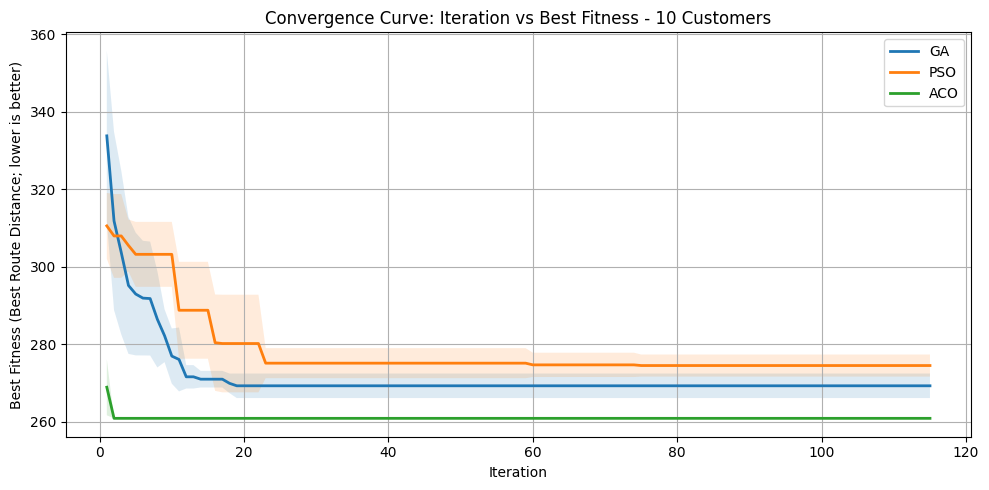

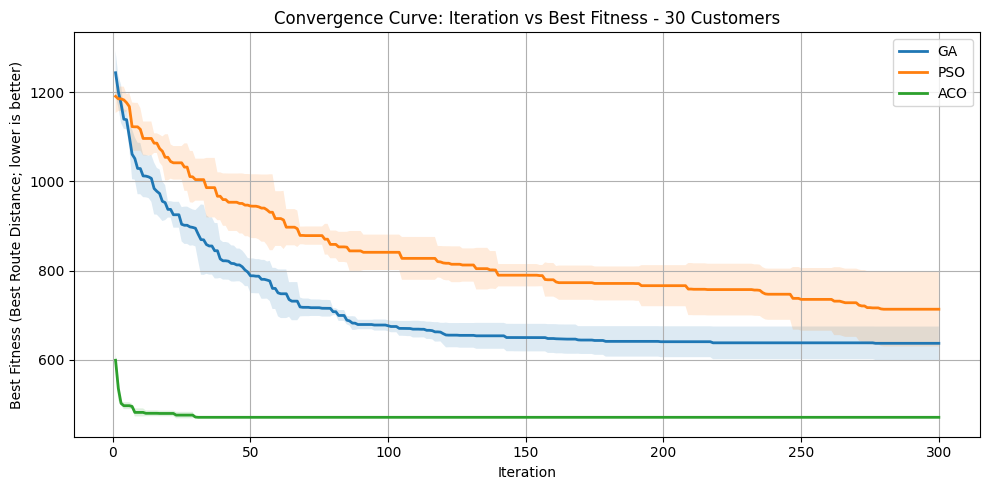

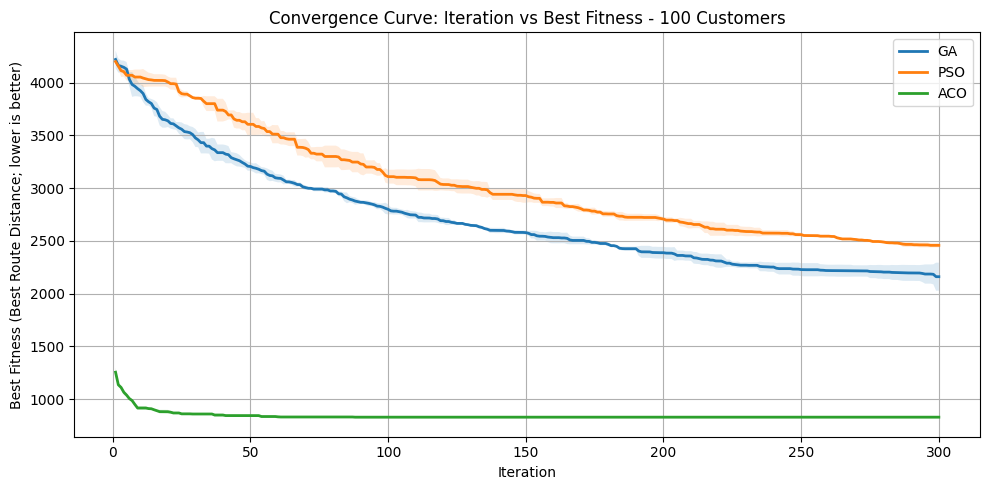


Results saved to: C:\Users\FPCC\Desktop\Intelligent Algorithms_BIA601\ITE_F25_BIA601_HW\Algorithms&data\results\three_run_comparison


In [16]:
if "manual_run_records" not in globals() or not manual_run_records:
    raise RuntimeError("No runs are stored. Execute the automatic three-run experiment cell first.")

runs_df = pd.DataFrame(manual_run_records)
convergence_df = pd.DataFrame(manual_convergence_records)
completed_runs = sorted(runs_df["Run"].unique().tolist())

if completed_runs != [1, 2, 3]:
    raise RuntimeError(
        f"Expected completed runs [1, 2, 3], but found {completed_runs}. "
        "Run the automatic experiment cell again before generating the final comparison."
    )

expected_rows = len(COMPARISON_SIZES) * len(ALGORITHM_NAMES) * 3
if len(runs_df) != expected_rows:
    raise RuntimeError(
        f"Expected {expected_rows} result rows, but found {len(runs_df)}. "
        "Check that the automatic experiment cell completed for all algorithms and sizes."
    )

print("Raw results by problem size: each row is one independent execution.")
for n_customers in COMPARISON_SIZES:
    size_table = (
        runs_df.loc[runs_df["Problem_Size"] == n_customers]
        .pivot(index="Run", columns="Algorithm", values="Best_Distance")
        .reindex(index=[1, 2, 3], columns=ALGORITHM_NAMES)
    )
    print(f"\n{n_customers} customers")
    display(size_table.round(4))

summary_df = (
    runs_df.groupby(["Problem_Size", "Algorithm"], as_index=False)
    .agg(
        Runs=("Best_Distance", "count"),
        Best=("Best_Distance", "min"),
        Worst=("Best_Distance", "max"),
        Mean=("Best_Distance", "mean"),
        Std_Dev=("Best_Distance", "std"),
        Mean_Time_s=("Execution_Time_s", "mean"),
        Mean_Evaluations=("Objective_Evaluations", "mean"),
        Mean_Iterations=("Iterations", "mean"),
    )
)
summary_df["CV_%"] = 100.0 * summary_df["Std_Dev"] / summary_df["Mean"]

print("\nStatistical comparison across the three independent runs")
display(summary_df.round(4))

PROJECT_ROOT = DATA_PATH.resolve().parent.parent if DATA_PATH.resolve().parent.name == "data" else Path.cwd()
RESULTS_DIR = PROJECT_ROOT / "results" / "three_run_comparison"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

runs_df.to_csv(RESULTS_DIR / "three_run_raw_results.csv", index=False)
summary_df.to_csv(RESULTS_DIR / "three_run_summary.csv", index=False)
convergence_df.to_csv(RESULTS_DIR / "three_run_convergence.csv", index=False)

for n_customers in COMPARISON_SIZES:
    size_curves = convergence_df[convergence_df["Problem_Size"] == n_customers]
    max_iteration = int(size_curves["Iteration"].max())
    iteration_grid = np.arange(1, max_iteration + 1)

    plt.figure(figsize=(10, 5))
    for algorithm in ALGORITHM_NAMES:
        algorithm_curves = size_curves[size_curves["Algorithm"] == algorithm]
        aligned_curves = []

        for _, run_curve in algorithm_curves.groupby("Run"):
            run_curve = run_curve.sort_values("Iteration")
            x_values = run_curve["Iteration"].to_numpy(dtype=float)
            y_values = run_curve["Best_Distance"].to_numpy(dtype=float)
            aligned_curves.append(
                np.interp(
                    iteration_grid,
                    x_values,
                    y_values,
                    left=y_values[0],
                    right=y_values[-1],
                )
            )

        curve_matrix = np.vstack(aligned_curves)
        mean_curve = curve_matrix.mean(axis=0)
        std_curve = curve_matrix.std(axis=0, ddof=1)
        plt.plot(iteration_grid, mean_curve, linewidth=2, label=algorithm)
        plt.fill_between(
            iteration_grid,
            np.maximum(0, mean_curve - std_curve),
            mean_curve + std_curve,
            alpha=0.15,
        )

    plt.title(f"Convergence Curve: Iteration vs Best Fitness - {n_customers} Customers")
    plt.xlabel("Iteration")
    plt.ylabel("Best Fitness (Best Route Distance; lower is better)")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig(
        RESULTS_DIR / f"iteration_vs_best_fitness_{n_customers}.png",
        dpi=160,
        bbox_inches="tight",
    )
    plt.show()

print(f"\nResults saved to: {RESULTS_DIR.resolve()}")
